[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/07_solvation_minimization.ipynb)

# 07 · Solvation, Ions, and Energy Minimization

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~45 min*

Proteins live in salty water, and water shapes everything they do. In this notebook we put the prepared
chignolin peptide into a periodic box of explicit water, add sodium and chloride ions to neutralize it and
reach physiological salt concentration, and then **minimize the energy** to remove bad contacts before any
dynamics. These are the first two steps of every MD workflow.

**Learning objectives.** By the end of this notebook you will be able to:

- solvate a protein in a periodic water box with a chosen padding and box shape
- add counter-ions and salt to a target ionic strength, and check the numbers by hand
- verify that the solute cannot interact with its own periodic image
- run and monitor an energy minimization, and explain why it is needed

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm', 'pdbfixer'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Prepare chignolin (recap of Notebook 06)

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit
from pdbfixer import PDBFixer

fixer = PDBFixer(filename=f"{DATA_DIR}/structures/5AWL.pdb")
fixer.removeHeterogens(keepWater=False)
fixer.findMissingResidues(); fixer.findMissingAtoms(); fixer.addMissingAtoms()
ff = app.ForceField("amber14-all.xml", "amber14/tip3pfb.xml")   # ff14SB protein + TIP3P-FB water and ions
model = app.Modeller(fixer.topology, fixer.positions)
model.addHydrogens(ff, pH=7.0)
n_protein = model.topology.getNumAtoms()
print("chignolin with hydrogens:", n_protein, "atoms")

chignolin with hydrogens: 166 atoms


## 2. Choosing a water model and box

The water model must match the force field: AMBER ff14SB is usually paired with TIP3P (here the improved
**TIP3P-FB**), CHARMM36m with its modified TIP3P, and modern AMBER ff19SB with OPC. `addSolvent` places a
pre-equilibrated water box around the solute, removes waters that overlap it, and adds ions. In OpenMM,
`padding` is the **guaranteed minimum distance between the solute and any of its periodic images** (the box
edge is the diameter of the solute's bounding sphere plus the padding). Careful when you move between programs:
GROMACS `gmx editconf -d 1.0` means 1.0 nm from the solute to each box face, i.e. about 2 nm between images.
Let us compare box shapes with the same 1.0 nm padding.

In [3]:
rows = []
for shape in ["cube", "dodecahedron", "octahedron"]:
    m = app.Modeller(model.topology, model.positions)
    m.addSolvent(ff, model="tip3p", padding=1.0 * unit.nanometer, boxShape=shape, ionicStrength=0.15 * unit.molar)
    vecs = m.topology.getPeriodicBoxVectors()
    vol = np.abs(np.linalg.det(np.array([v.value_in_unit(unit.nanometer) for v in vecs])))
    rows.append({"box": shape, "volume (nm3)": vol, "waters": sum(r.name == "HOH" for r in m.topology.residues()),
                 "atoms": m.topology.getNumAtoms()})
pd.DataFrame(rows).round(1)

,box,volume (nm3),waters,atoms
0,cube,35.8,1027,3255
1,dodecahedron,25.3,689,2239
2,octahedron,27.6,753,2431


The dodecahedron and octahedron give the same solute–image separation as the cube with fewer waters, so they
are cheaper for globular proteins. Here we keep the cube because it is the easiest to picture; Notebook 11 uses
an octahedron for the much larger kinase.

## 3. Solvate and add ions

In [4]:
model.addSolvent(ff, model="tip3p", padding=1.0 * unit.nanometer, ionicStrength=0.15 * unit.molar,
                 positiveIon="Na+", negativeIon="Cl-", neutralize=True)
counts = pd.Series([r.name for r in model.topology.residues()]).value_counts()
box = model.topology.getUnitCellDimensions().value_in_unit(unit.nanometer)
print("residues:", counts.to_dict())
print(f"box: {box[0]:.3f} x {box[1]:.3f} x {box[2]:.3f} nm, {model.topology.getNumAtoms()} atoms")

residues: {'HOH': 1027, 'NA': 5, 'CL': 3, 'TYR': 3, 'THR': 2, 'ASP': 1, 'GLY': 1, 'GLU': 1, 'PRO': 1, 'TRP': 1}
box: 3.297 x 3.297 x 3.297 nm, 3255 atoms


Check the ion numbers by hand. Chignolin has a net charge of −2 (Notebook 06), so 2 extra Na⁺ neutralize it.
For 0.15 M salt OpenMM estimates the number of ion pairs from the number of waters, using about 55.4 mol/L
for pure water: $n_{pairs} \approx 0.15 \times N_{water} / 55.4$.

In [5]:
n_wat = counts["HOH"]
print(f"waters: {n_wat}; expected NaCl pairs ~ {0.15 * n_wat / 55.4:.1f}")
print(f"Na+: {counts.get('NA', 0)}, Cl-: {counts.get('CL', 0)}  (difference {counts.get('NA', 0) - counts.get('CL', 0)} = counter-ions)")

waters: 1027; expected NaCl pairs ~ 2.8
Na+: 5, Cl-: 3  (difference 2 = counter-ions)


## 4. Can the peptide see its own image?

The minimum distance between any solute atom and any atom of its periodic images must exceed the non-bonded
cutoff (1.0 nm), otherwise the peptide would interact with itself across the boundary.

In [6]:
X = np.array(model.positions.value_in_unit(unit.nanometer))[:n_protein]
L = np.array(box)
d_min = np.inf
for shift in [(i, j, k) for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1) if (i, j, k) != (0, 0, 0)]:
    img = X + np.array(shift) * L
    d = np.linalg.norm(X[:, None, :] - img[None, :, :], axis=-1).min()
    d_min = min(d_min, d)
print(f"closest solute-image distance: {d_min:.2f} nm (cutoff 1.0 nm) -> {'OK' if d_min > 1.0 else 'TOO SMALL'}")

closest solute-image distance: 1.43 nm (cutoff 1.0 nm) -> OK


OpenMM guarantees at least the padding (1.0 nm) in the starting structure; the measured value is larger
because the box is built around a bounding *sphere* and the peptide is not spherical. A flexible or unfolding
protein can rotate or stretch towards its image during a run, so check this again on the trajectory, and use a
padding somewhat larger than the cutoff for proteins that change shape.

## 5. Build the System and look at the starting forces

In [7]:
system = ff.createSystem(model.topology, nonbondedMethod=app.PME, nonbondedCutoff=1.0 * unit.nanometer,
                         constraints=app.HBonds)
integrator = openmm.LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, 0.002 * unit.picoseconds)
sim = app.Simulation(model.topology, system, integrator, openmm.Platform.getPlatformByName("CPU"))
sim.context.setPositions(model.positions)

def report(label):
    st = sim.context.getState(getEnergy=True, getForces=True)
    f = np.linalg.norm(st.getForces(asNumpy=True).value_in_unit(unit.kilojoule_per_mole / unit.nanometer), axis=1)
    worst = int(f.argmax())
    atom = list(model.topology.atoms())[worst]
    print(f"{label:>7}: E = {st.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole):12.1f} kJ/mol | "
          f"max force {f.max():10.1f} kJ/mol/nm on {atom.residue.name}{atom.residue.id}:{atom.name}")
    return f
f_before = report("before")

 before: E =     -25486.7 kJ/mol | max force   181927.4 kJ/mol/nm on HOH108:O


## 6. Energy minimization

Hydrogens placed by rules and waters cut from a pre-made box create strained bonds and close contacts. With such
forces the first MD steps would accelerate atoms violently. **Minimization** (OpenMM uses the L-BFGS algorithm)
moves atoms downhill to the nearest local minimum. It is not a search for the global minimum and has nothing to
do with temperature: it just removes the worst strain. We record the energy along the way with a
`MinimizationReporter`.

minimization: 3989 iterations in 41.6 s
  after: E =     -63149.8 kJ/mol | max force     2588.0 kJ/mol/nm on HOH429:O


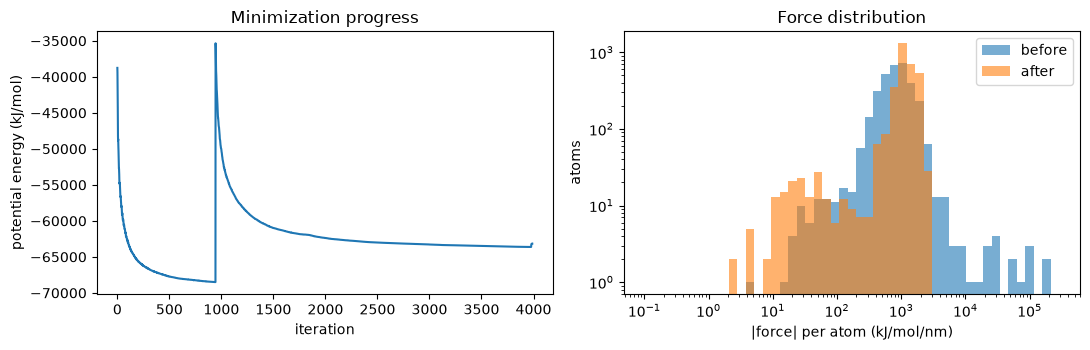

In [8]:
class Recorder(openmm.MinimizationReporter):
    energies = []
    def report(self, iteration, x, grad, args):
        self.energies.append(args["system energy"])
        return False                       # returning True would stop the minimizer

rec = Recorder()
t0 = time.time()
sim.minimizeEnergy(tolerance=10 * unit.kilojoule_per_mole / unit.nanometer, reporter=rec)
print(f"minimization: {len(rec.energies)} iterations in {time.time() - t0:.1f} s")
f_after = report("after")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(rec.energies); ax[0].set(xlabel="iteration", ylabel="potential energy (kJ/mol)", title="Minimization progress")
bins = np.logspace(-1, max(4.5, np.log10(f_before.max()) + 0.2), 50)
ax[1].hist(f_before, bins=bins, alpha=0.6, label="before"); ax[1].hist(f_after, bins=bins, alpha=0.6, label="after")
ax[1].set(xscale="log", yscale="log", xlabel="|force| per atom (kJ/mol/nm)", ylabel="atoms", title="Force distribution")
ax[1].legend(); plt.tight_layout(); plt.show()

The potential energy drops and, more importantly, the **largest forces** fall by orders of magnitude. The
`tolerance` argument stops the minimizer when the root-mean-square force is below the given value; the default
(10 kJ/mol/nm) is fine before MD.

## 7. Save the minimized system

Save both the coordinates (PDB, readable anywhere) and the exact OpenMM state (XML, including box vectors),
so that the next stage starts from precisely this point.

In [9]:
import os
os.makedirs("output", exist_ok=True)
state = sim.context.getState(getPositions=True, getEnergy=True)
app.PDBFile.writeFile(sim.topology, state.getPositions(), open("output/chignolin_minimized.pdb", "w"))
with open("output/chignolin_minimized_state.xml", "w") as fh:
    fh.write(openmm.XmlSerializer.serialize(state))
print("saved output/chignolin_minimized.pdb and output/chignolin_minimized_state.xml")

saved output/chignolin_minimized.pdb and output/chignolin_minimized_state.xml


### ✏️ Exercise 1

Solvate chignolin with a **0.6 nm** padding (cube) instead of 1.0 nm. How many waters do you save, and what is
the closest solute–image distance now? Would that be acceptable with a 1.0 nm cutoff?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
m = app.Modeller(fixer.topology, fixer.positions); m.addHydrogens(ff, pH=7.0)
m.addSolvent(ff, padding=0.6 * unit.nanometer, ionicStrength=0.15 * unit.molar)
Lb = np.array(m.topology.getUnitCellDimensions().value_in_unit(unit.nanometer))
Xp = np.array(m.positions.value_in_unit(unit.nanometer))[:n_protein]
dmin = min(np.linalg.norm(Xp[:, None] - (Xp + np.array(s) * Lb)[None], axis=-1).min()
           for s in [(i, j, k) for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1) if (i, j, k) != (0, 0, 0)])
print(sum(r.name == "HOH" for r in m.topology.residues()), "waters; closest image", round(dmin, 2), "nm")
```

</details>

### ✏️ Exercise 2

Run 200 steps of dynamics (2 fs) from the **unminimized** coordinates and from the minimized ones, printing the
temperature every 20 steps. Use a fresh `Simulation` for the unminimized case. What happens in the first few
steps? (Use `app.StateDataReporter(sys.stdout, 20, step=True, temperature=True)`.)

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for label, pos in [("unminimized", model.positions), ("minimized", state.getPositions())]:
    integ = openmm.LangevinMiddleIntegrator(300, 1, 0.002); integ.setRandomNumberSeed(1)
    s = app.Simulation(model.topology, system, integ, openmm.Platform.getPlatformByName("CPU"))
    s.context.setPositions(pos); s.context.setVelocitiesToTemperature(300, 1)
    s.reporters.append(app.StateDataReporter(sys.stdout, 20, step=True, temperature=True))
    print(label); s.step(200)
```

</details>

### ✏️ Exercise 3

Add salt at **0.5 M** instead of 0.15 M to a fresh copy of the prepared peptide. How many Na⁺ and Cl⁻ ions are
added? Does it match the formula above?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
m = app.Modeller(fixer.topology, fixer.positions); m.addHydrogens(ff, pH=7.0)
m.addSolvent(ff, padding=1.0 * unit.nanometer, ionicStrength=0.5 * unit.molar)
c = pd.Series([r.name for r in m.topology.residues()]).value_counts()
print(c[["NA", "CL"]].to_dict(), "| formula:", round(0.5 * c["HOH"] / 55.4, 1), "pairs")
```

</details>

## Key takeaways

- Solvate with a force-field-matched water model, padding ≥ the cutoff (OpenMM padding = solute–image distance), and 0.15 M salt plus counter-ions.
- Dodecahedron/octahedron boxes need about 25–35% less water than a cube.
- Check that the solute–image distance exceeds the cutoff.
- Minimize before MD: it removes huge initial forces; save the minimized state for the next stage.

**Next:** [08 · Equilibration and production](08_equilibration_production.ipynb).